<a href="https://colab.research.google.com/github/moiz-shahid/Deep-Learning-Tutorials/blob/main/Tutorial-06-Transfer-Learning/DL_Tutorial_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn.functional as F
import torchvision.models as models
import matplotlib.pyplot as plt

from PIL import Image
from torchvision.models import (
    VGG16_Weights,
    ResNet50_Weights
)
from google.colab import files

In [10]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


Using device: cuda


Saving images.jpg to images.jpg


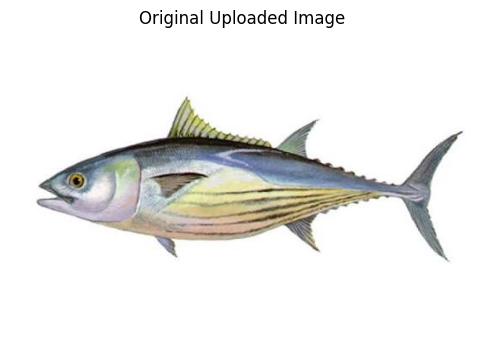

In [11]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title("Original Uploaded Image")
plt.axis("off")
plt.show()

In [12]:
vgg_weights = VGG16_Weights.DEFAULT
resnet_weights = ResNet50_Weights.DEFAULT

vgg_model = models.vgg16(
    weights=vgg_weights
).to(device)

resnet_model = models.resnet50(
    weights=resnet_weights
).to(device)

vgg_model.eval()
resnet_model.eval()

print("VGG16 and ResNet50 loaded successfully.")

VGG16 and ResNet50 loaded successfully.


In [13]:
vgg_transform = vgg_weights.transforms()
resnet_transform = resnet_weights.transforms()

vgg_input = vgg_transform(image).unsqueeze(0).to(device)

resnet_input = resnet_transform(image).unsqueeze(0).to(device)

print("VGG16 input shape:", vgg_input.shape)
print("ResNet50 input shape:", resnet_input.shape)

VGG16 input shape: torch.Size([1, 3, 224, 224])
ResNet50 input shape: torch.Size([1, 3, 224, 224])


In [14]:
def predict_top5(model, input_tensor, weights):

    model.eval()

    with torch.no_grad():
        outputs = model(input_tensor)

        probabilities = F.softmax(outputs, dim=1)

        top_probs, top_indices = torch.topk(
            probabilities, 5, dim=1
        )

    class_names = weights.meta["categories"]

    results = []

    for probability, index in zip(
        top_probs[0], top_indices[0]
    ):
        class_name = class_names[index.item()]
        percentage = probability.item() * 100

        results.append((class_name, percentage))

    return results

In [15]:
vgg_results = predict_top5(
    vgg_model,
    vgg_input,
    vgg_weights
)

print("Top 5 Predictions from VGG16:\n")

for i, (label, probability) in enumerate(vgg_results, 1):
    print(f"{i}. {label}: {probability:.2f}%")

Top 5 Predictions from VGG16:

1. barracouta: 80.22%
2. rock beauty: 7.03%
3. tench: 4.52%
4. quill: 3.79%
5. coho: 0.86%


In [16]:
resnet_results = predict_top5(
    resnet_model,
    resnet_input,
    resnet_weights
)

print("Top 5 Predictions from ResNet50:\n")

for i, (label, probability) in enumerate(resnet_results, 1):
    print(f"{i}. {label}: {probability:.2f}%")

Top 5 Predictions from ResNet50:

1. barracouta: 64.48%
2. gar: 2.60%
3. reel: 1.10%
4. tench: 0.69%
5. rock beauty: 0.51%


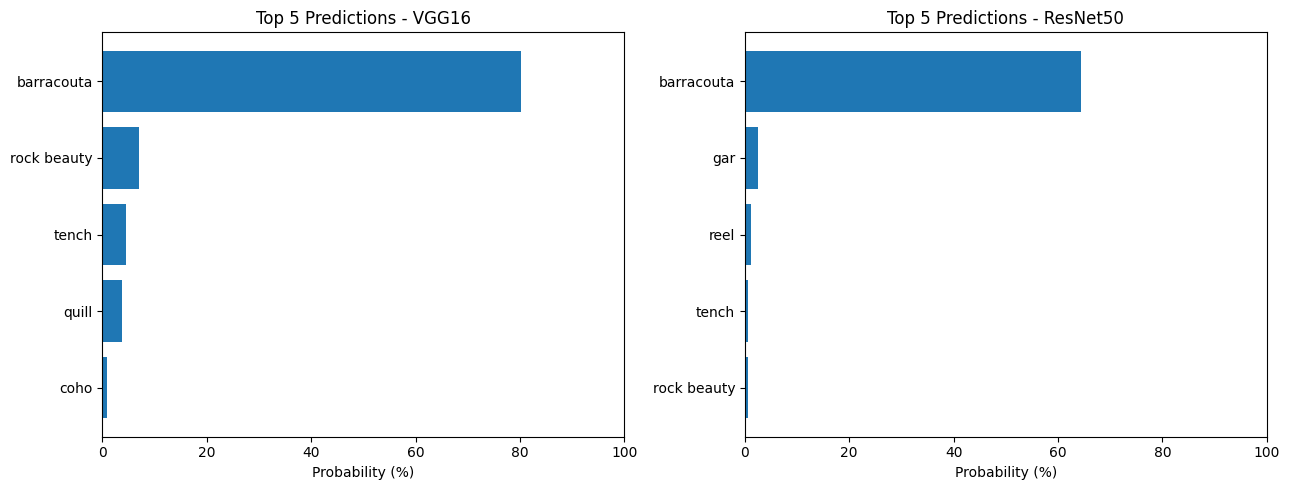

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, results, name in zip(
    axes,
    [vgg_results, resnet_results],
    ["VGG16", "ResNet50"]
):
    labels = [item[0] for item in results]
    probs = [item[1] for item in results]

    ax.barh(labels[::-1], probs[::-1])
    ax.set_xlabel("Probability (%)")
    ax.set_title(f"Top 5 Predictions - {name}")
    ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

# Task 2 — Compare different pretrained architectures

In [18]:
from torchvision.models import (
    AlexNet_Weights,
    ResNet101_Weights,
    MobileNet_V2_Weights
)

model_configs = {
    "AlexNet": (
        models.alexnet,
        AlexNet_Weights.DEFAULT
    ),
    "ResNet101": (
        models.resnet101,
        ResNet101_Weights.DEFAULT
    ),
    "MobileNetV2": (
        models.mobilenet_v2,
        MobileNet_V2_Weights.DEFAULT
    )
}

In [19]:
comparison_results = {}

for name, (model_fn, weights) in model_configs.items():

    print(f"\nLoading {name}...")

    model = model_fn(weights=weights).to(device)
    model.eval()

    transform = weights.transforms()
    input_tensor = transform(image).unsqueeze(0).to(device)

    results = predict_top5(model, input_tensor, weights)

    comparison_results[name] = results

    print(f"\nTop 5 Predictions from {name}:")

    for i, (label, probability) in enumerate(results, 1):
        print(f"{i}. {label}: {probability:.2f}%")

    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()


Loading AlexNet...
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 172MB/s]



Top 5 Predictions from AlexNet:
1. barracouta: 48.83%
2. grasshopper: 15.36%
3. gar: 12.38%
4. cricket: 9.33%
5. bee eater: 3.46%

Loading ResNet101...
Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:00<00:00, 185MB/s]



Top 5 Predictions from ResNet101:
1. barracouta: 89.56%
2. rock beauty: 0.62%
3. tench: 0.58%
4. gar: 0.22%
5. reel: 0.19%

Loading MobileNetV2...
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 123MB/s]



Top 5 Predictions from MobileNetV2:
1. barracouta: 23.33%
2. tench: 9.99%
3. coho: 7.10%
4. gar: 2.46%
5. ground beetle: 0.87%


## Task 2: Comparison of Different Pretrained Architectures

Five pretrained ImageNet classification models were tested using the same uploaded image: VGG16, ResNet50, AlexNet, ResNet101, and MobileNetV2.

| Model | Top Predicted Class | Probability |
|---|---|---:|
| VGG16 | Barracouta | 80.22% |
| ResNet50 | Barracouta | 64.48% |
| AlexNet | Barracouta | 48.83% |
| ResNet101 | Barracouta | 89.56% |
| MobileNetV2 | Barracouta | 23.33% |

### Observations

All five models predicted the same top class, **barracouta**, showing agreement across different pretrained architectures.

However, their predicted probabilities varied. ResNet101 produced the highest probability at 89.56%, while MobileNetV2 produced the lowest at 23.33%.

These differences may arise from architectural differences, learned features, and the calibration of model outputs.



# Task 3 — Transfer learning on a dataset

In [23]:
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Subset

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Smaller subsets for faster Colab experiments
train_subset = Subset(train_dataset, range(5000))
test_subset = Subset(test_dataset, range(1000))

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_subset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(train_subset))
print("Testing samples:", len(test_subset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 506kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.67MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.8MB/s]

Training samples: 5000
Testing samples: 1000


In [25]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torchvision.models import ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained ResNet18
weights = ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

print("Original output layer:")
print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 70.4MB/s]


Original output layer:
Linear(in_features=512, out_features=1000, bias=True)


In [26]:
# Freeze all pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final layer for MNIST
model.fc = nn.Linear(
    model.fc.in_features,
    10
)

model = model.to(device)

print("Modified output layer:")
print(model.fc)

Modified output layer:
Linear(in_features=512, out_features=10, bias=True)


In [27]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [28]:
epochs = 5

train_losses = []
train_accuracies = []

for epoch in range(epochs):

    model.eval()  # Keep frozen BatchNorm layers in evaluation mode
    model.fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 1.2760 Accuracy: 71.40%
Epoch [2/5] Loss: 0.5630 Accuracy: 89.52%
Epoch [3/5] Loss: 0.3989 Accuracy: 92.22%
Epoch [4/5] Loss: 0.3245 Accuracy: 92.98%
Epoch [5/5] Loss: 0.2755 Accuracy: 94.10%


In [29]:
model.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_loss = test_loss / total
test_accuracy = 100 * correct / total

print("Test Accuracy:", round(test_accuracy, 2), "%")
print("Test Loss:", round(test_loss, 4))

Test Accuracy: 92.3 %
Test Loss: 0.3155


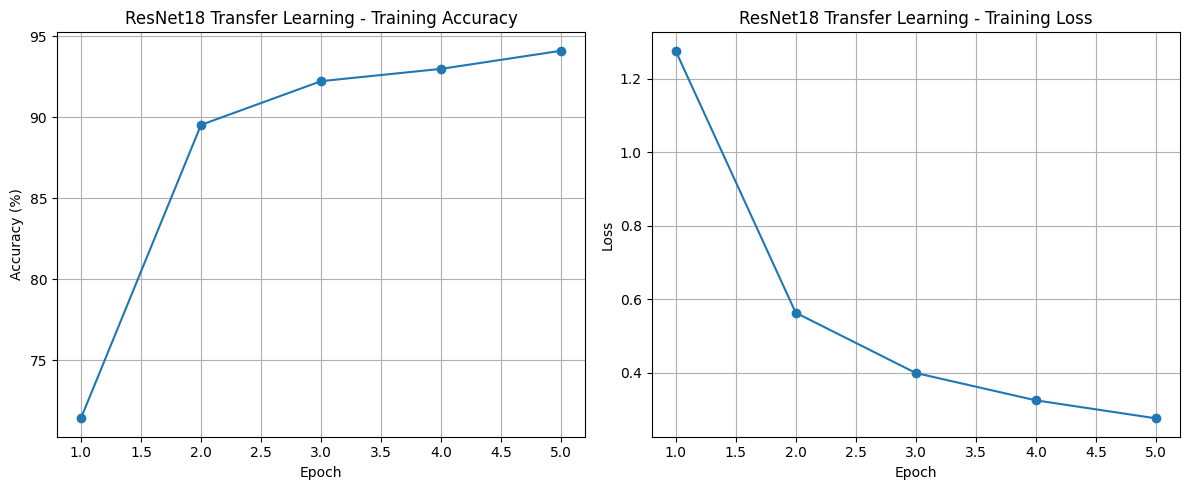

In [30]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_accuracies, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet18 Transfer Learning - Training Accuracy")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet18 Transfer Learning - Training Loss")
plt.grid()

plt.tight_layout()
plt.show()

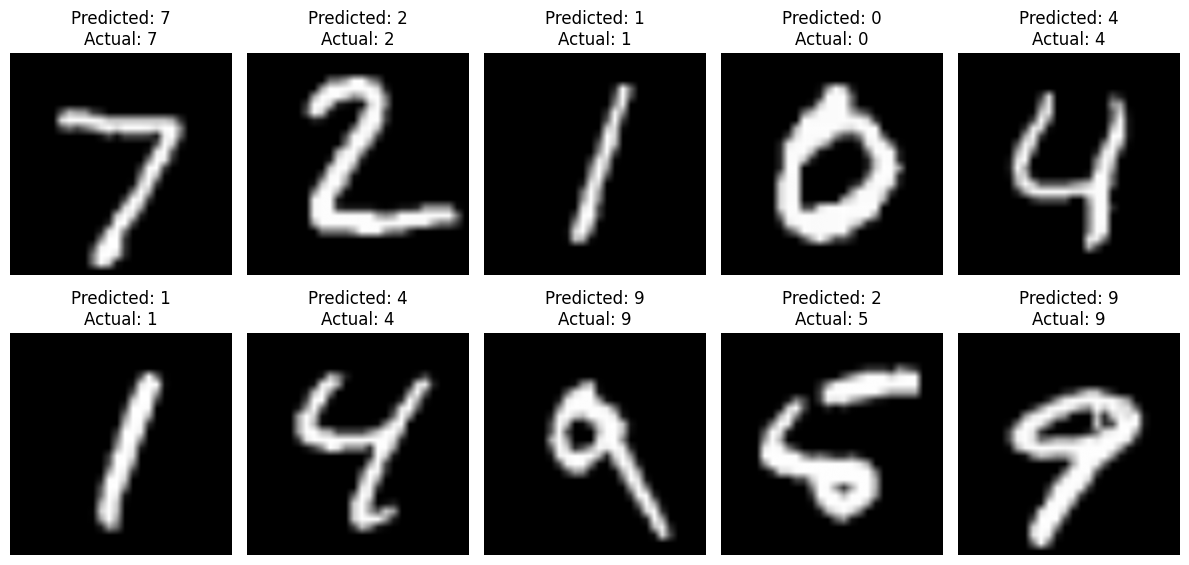

In [31]:
model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    # Show original MNIST grayscale image
    original_image, _ = test_dataset[i]

    # Undo normalization for display
    image = original_image[0] * 0.229 + 0.485

    plt.imshow(image, cmap="gray")
    plt.title(
        f"Predicted: {predictions[i].item()}\n"
        f"Actual: {labels[i].item()}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## Task 3: Transfer Learning Using ResNet18 on MNIST

### Objective

The objective of this experiment was to demonstrate transfer learning by adapting a pretrained ResNet18 model to classify handwritten digits from the MNIST dataset.

### Implementation

ResNet18 was loaded with pretrained ImageNet weights.

The pretrained feature-extraction layers were frozen, and the original fully connected classification layer was replaced with a new layer containing 10 output neurons, corresponding to digits 0–9.

MNIST images were converted from grayscale to three channels, resized to 224×224 pixels, and normalized using ImageNet preprocessing values.

A subset of 5,000 training images and 1,000 testing images was used to reduce computational requirements.

The new classification layer was trained for five epochs using the Adam optimizer and cross-entropy loss.

### Results

| Metric | Result |
|---|---:|
| Training Samples | 5,000 |
| Testing Samples | 1,000 |
| Training Epochs | 5 |
| Final Training Accuracy | 94.10% |
| Final Training Loss | 0.2755 |
| Test Accuracy | 92.30% |
| Test Loss | 0.3155 |

### Observations

Training accuracy increased from 71.40% in the first epoch to 94.10% in the fifth epoch.

Training loss decreased from 1.2760 to 0.2755, demonstrating that the new classifier successfully learned to distinguish handwritten digits.

The model achieved 92.30% accuracy on the test subset, indicating that the transferred feature representations were useful for this classification task.

The relatively small difference between final training and test accuracy suggests reasonable generalization, although a separate validation experiment would be needed for a more complete overfitting analysis.
